In [ ]:
#
#
# FINANCE CONCEPTS
# 
# So far we have seen:
# - Daily Returns 
# - Avg Daily Return (mean of daily returns)
# - Std Daily return (Standard deviation of daily returns)
# - Cumulative Returns 

In [ ]:
#
# SHARPE RATION (after William Sharpe)
#
#        ( R_p  -  R_f )                                      R_p
#   S = ------------------  ---------( if R_f ==0 )----> = --------- 
#            Sigma_p                                        Sigma_p 
#
# where
#   R_p is the Expected Portfolio Return (i.e. the Avg Daily Return)
#   R_f is the Risk Free Return (this is by mostly conisdered to be zero)
#       you could also consider the interests of a bank account or stable state bonds, etc..
#       In the UK could use ISA saving account I guess.. though you can only invest 20k (and now less) there  
#   Sigma_p is the portfolio Standard Deviation  
#
# This is a way to quantify the relationship between Mean Daily Return
# and the volatility (standard deviation) of a portfolio
#
#
# Note that comparing portfolios:
#
# - if both have low volatility and one mean daily return is higher you would go for that
# - same if they have the same mean average but one is more volatile, you would go for the one more stable (less risk)
# - if one is more volatile but also have higher mean return, it would be harder to choose

In [3]:
# NOTE:
# this is supposed the Yearly Mean Return and Yearly Standard Deviation
# If you use instead daily/weekly/monthly values 
# You MUST adjust it and in particular (the mean won't change but the STD does change when)
# and in particular it's smaller than the yearly one (fewer samples and remember you sum variance)
# So Annual Sharpe Ratio (ASR) is
#
#  ASR  == K * SR
#
# where 
#   if SR is based on daily values, K = sqrt(252)   # 252 working days in a year 
#   if SR is based on weekly values, K = sqrt(52)    # 52 weeks s in a year #   if SR is based on daily values, 
#   if SR is based on monthly values, K = sqrt(12)    # 12 months in a year 
#

In [65]:
#
#
# Quandl is used in the videos however..
# not installable with latest python so..
# remember these 2 options work (so far):
#  1. 
#  import pandas_datareader as web
#  apple_df = web.DataReader('AAPL', 'stooq', start, end)  # GOOGLE API DOES NOT WORK
#  2.
#  import yfinance as yf
#  ticker = 'AAPL'  (but you can get multiple stocks at once with tickers = [ "<stock1>", ... ] )
#  df = yf.download(tickers='AAPL', start=start_date, end=end_date, interval="1d", auto_adjust=True, progress=False)
import pandas as pd
import pandas_datareader as web
import yfinance as yf
import pprint
start_date = pd.to_datetime('2020-01-01')
end_date = pd.to_datetime('2025-01-01')
#
# Note that datareader gives the results from the most recent to the oldest
# so we kinda need to flip them around
apple_df1 = web.DataReader('AAPL', 'stooq', start=start_date, end=end_date)[::-1] 
apple_df2 = yf.download(tickers='AAPL', start=start_date, end=end_date, interval="1d", auto_adjust=True, progress=False)
pprint.pprint(apple_df1.head())
print("---------------")
pprint.pprint(apple_df2.head()) # <-- this has tuples as columns so need to reset them
print("--------------")


               Open     High      Low    Close     Volume
Date                                                     
2020-01-02  71.7196  72.7764  71.4646  72.7161  140071218
2020-01-03  71.9425  72.7725  71.7839  72.0115  151314357
2020-01-06  71.1246  72.6207  70.8782  72.5811  122445682
2020-01-07  72.5909  72.8502  72.0233  72.2432  115147229
2020-01-08  71.9444  73.7056  71.9425  73.4042  136680453
---------------
Price           Close       High        Low       Open     Volume
Ticker           AAPL       AAPL       AAPL       AAPL       AAPL
Date                                                             
2020-01-02  72.468277  72.528597  71.223274  71.476615  135480400
2020-01-03  71.763718  72.523746  71.539330  71.696160  146322800
2020-01-06  72.335564  72.374169  70.634547  70.885479  118387200
2020-01-07  71.995361  72.600968  71.775796  72.345212  108872000
2020-01-08  73.153511  73.455110  71.698596  71.698596  132079200
--------------


In [66]:
new_columns = ['Close', 'High', 'Low', 'Open', 'Volume']
apple_df2.columns = new_columns
apple_df2.head()

,Close,High,Low,Open,Volume
Date,,,,,
2020-01-02,72.468277,72.528597,71.223274,71.476615,135480400
2020-01-03,71.763718,72.523746,71.539330,71.696160,146322800
2020-01-06,72.335564,72.374169,70.634547,70.885479,118387200
2020-01-07,71.995361,72.600968,71.775796,72.345212,108872000
2020-01-08,73.153511,73.455110,71.698596,71.698596,132079200


In [67]:
#
# Now we create a portfolio with
# - CISCO
# - IBM
# - AMAZON
cisco_df1 = web.DataReader('CSCO', 'stooq', start_date, end_date)[::-1]
IBM_df1 = web.DataReader('IBM', 'stooq', start_date, end_date) [::-1]
AMAZON_df1 = web.DataReader('AMZN', 'stooq', start_date, end_date) [::-1]


In [68]:
#
# we only care about Close values so we remove everything else
aapl = pd.DataFrame(apple_df2['Close'], columns=[ 'Close'])
csco = pd.DataFrame(cisco_df1['Close'], columns=[ 'Close'])
ibm = pd.DataFrame(IBM_df1['Close'], columns=[ 'Close'])
amazn = pd.DataFrame(AMAZON_df1['Close'], columns=[ 'Close'])

In [69]:
#
#. BASIC METRICS -  Cumulative Return
#. 
for stock_df in [ aapl ,csco, ibm, amazn ]:
    stock_df['Normed Return'] = stock_df['Close'] / stock_df.iloc[0]['Close']

In [70]:
csco.head()

,Close,Normed Return
Date,,
2020-01-02,44.4179,1.000000
2020-01-03,43.6932,0.983685
2020-01-06,43.8494,0.987201
2020-01-07,43.5637,0.980769
2020-01-08,43.5921,0.981408


In [71]:
#
# Let's pretend we have some allocation :  30% apple,  20% cisco,  40% amazn, 10% ibm
#
money_invested = 10000
for stock_df, allo in zip([ aapl ,csco, ibm, amazn ], [ .3, .2, .4, .1 ]):
    stock_df['Allocation'] = stock_df['Normed Return'] * allo
    stock_df['Position'] = stock_df['Allocation'] * money_invested
#
#     
aapl.head()    

,Close,Normed Return,Allocation,Position
Date,,,,
2020-01-02,72.468277,1.000000,0.300000,3000.000000
2020-01-03,71.763718,0.990278,0.297083,2970.833059
2020-01-06,72.335564,0.998169,0.299451,2994.506010
2020-01-07,71.995361,0.993474,0.298042,2980.422510
2020-01-08,73.153511,1.009456,0.302837,3028.366925


In [73]:
#
# Now we put all the stocks together
# 
all_positions = [ x['Position'] for x in [ aapl ,csco, ibm, amazn ] ]
#
# important to specify the Y axis as the axis
portfolio_df = pd.concat(all_positions, axis = 1)
portfolio_df.columns = ['AAPL Position', 'CSCO Position','IBM Position','AMAZN Position', ]
#
# Note the axis is 1 because I run the df in vertical
portfolio_df['Total'] = portfolio_df.sum(axis=1)
portfolio_df.head()

,AAPL Position,CSCO Position,IBM Position,AMAZN Position,Total
Date,,,,,
2020-01-02,3000.000000,2000.000000,4000.000000,1000.000000,10000.000000
2020-01-03,2970.833059,1967.369011,3967.923235,987.860970,9893.986275
2020-01-06,2994.506010,1974.402212,3960.555175,1002.565845,9932.029242
2020-01-07,2980.422510,1961.538029,3963.536669,1004.662778,9910.159986
2020-01-08,3028.366925,1962.816792,3996.675805,996.817720,9984.677243


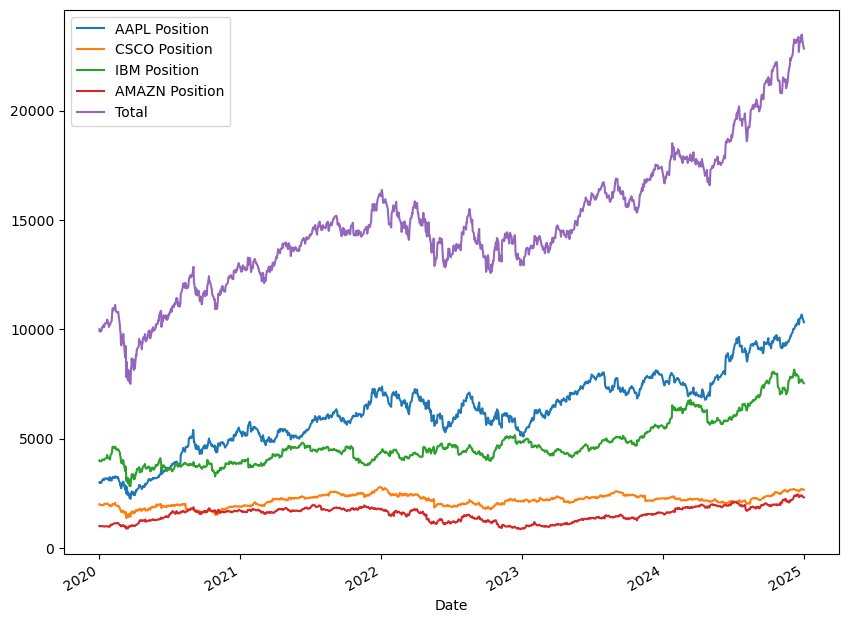

In [74]:
import matplotlib.pyplot as plt
%matplotlib inline
portfolio_df.plot(figsize=(10,8))
plt.legend()